# 02 - Feature Engineering, Modelling & Evaluation
Predict whether a customer will churn, compare models fairly, pick one **without touching the test set**, then evaluate it once.

**Protocol**
1. Stratified 80/20 split (seed 42). The 20% test set is used **only** for the final evaluation.
2. All preprocessing / feature engineering lives inside an sklearn `Pipeline` -> fitted only on training folds (no leakage).
3. Compare candidates with 5-fold stratified CV on the training split (ROC-AUC primary, PR-AUC secondary).
4. Tune each family with `RandomizedSearchCV`; select the best by mean CV ROC-AUC.
5. Choose the decision threshold using **out-of-fold** predictions on the training split.
6. Evaluate on the hold-out test set, with bootstrap confidence intervals.

> XGBoost / LightGBM were not available in the environment used to build this project, so scikit-learn's `GradientBoostingClassifier` and `HistGradientBoostingClassifier` represent boosted trees.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, joblib, matplotlib.pyplot as plt
from src import config as C, plots as P
from src.data import load_raw, clean, model_frame, split
from src.features import engineer
from src.train import step_baseline, step_ablation, step_tune, step_final
P.set_style()
pd.set_option("display.max_columns", 50, "display.width", 150, "display.max_colwidth", 120)

def show(name, w=None):
    img = plt.imread(C.FIG_DIR / name)
    fig, ax = plt.subplots(figsize=(w or 10, (w or 10) * img.shape[0] / img.shape[1]))
    ax.imshow(img); ax.axis("off"); fig.subplots_adjust(0, 0, 1, 1)

## 1. Data and split

In [2]:
df = clean(load_raw())
X, y = model_frame(df)
Xtr, Xte, ytr, yte = split(X, y)
print("features used (18 raw columns):", list(X.columns))
print(f"train {Xtr.shape}  test {Xte.shape}  | churn rate train {ytr.mean():.4f}  test {yte.mean():.4f}")

features used (18 raw columns): ['senior_citizen', 'partner', 'dependents', 'tenure_months', 'phone_service', 'multiple_lines', 'internet_service', 'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies', 'contract', 'paperless_billing', 'payment_method', 'monthly_charges', 'total_charges']
train (5634, 18)  test (1409, 18)  | churn rate train 0.2654  test 0.2654


## 2. Feature engineering (inside the pipeline)

In [3]:
eng = engineer(Xtr)
print("raw ->", Xtr.shape[1], "columns;  engineered ->", eng.shape[1], "columns")
eng.head(5).T

raw -> 18 columns;  engineered -> 25 columns


,4626,4192,5457,4717,4673
senior_citizen,0,0,0,0,0
partner,0,1,1,1,1
dependents,0,1,1,0,1
phone_service,0,1,0,1,1
multiple_lines,0,0,0,0,0
paperless_billing,0,0,0,1,0
autopay,0,0,0,1,0
has_internet,1,1,1,1,1
online_security,0,1,1,0,0
online_backup,0,0,1,1,0


| New feature | Meaning |
|---|---|
| `n_addons`, `n_protective` | number of subscribed add-on services (all six / only security, backup, device protection, tech support) |
| `avg_monthly_spend` | `total_charges / tenure` (current monthly charge for tenure 0) |
| `charge_gap` | current monthly charge - historical average (proxy for a recent price increase) |
| `autopay` | pays by bank transfer / credit card automatically |
| `has_internet` | any internet service |
| `tenure_bucket` | 0-6, 7-12, 13-24, 25-48, 49+ months |

'No internet service' / 'No phone service' are collapsed to *No* because `internet_service` / `phone_service` already carry that information.

## 3. Baseline: default-parameter models (5-fold out-of-fold, training split)

In [4]:
baseline = step_baseline(Xtr, ytr)
baseline.round(4)

,oof_roc_auc,oof_pr_auc,oof_brier,seconds
Dummy (prior),0.4999,0.2653,0.1949,0.1
Logistic Regression,0.8601,0.6797,0.1294,0.2
Random Forest,0.8407,0.6395,0.1388,5.7
Gradient Boosting,0.8591,0.6691,0.1312,3.3
HistGradientBoosting,0.8466,0.6422,0.1392,1.2


A dummy classifier gives AUC 0.50 (sanity check). A well-regularised linear model is already very strong on this dataset, which is common for clean, low-dimensional tabular data with mostly categorical signals.

## 4. Ablation: which extra columns help, and which would be cheating?

In [5]:
ablation = step_ablation(df, Xtr, ytr)
ablation.round(4)

,Logistic Regression OOF AUC,HistGradientBoosting OOF AUC
Production feature set,0.8601,0.8466
+ gender,0.8600,0.8474
+ latitude/longitude,0.8598,0.8502
+ CLTV (IBM-derived),0.8601,0.8475
+ Churn Score (IBM model output) [LEAKAGE],0.9760,0.9812


In [6]:
base_lr = ablation.iloc[0, 0]; leak_lr = ablation.iloc[-1, 0]
print(f"Adding IBM's Churn Score lifts Logistic-Regression OOF AUC from {base_lr:.3f} to {leak_lr:.3f} - that is leakage, not skill.")
print("Gender, lat/long and CLTV change AUC by < 0.005 -> excluded to keep the model simple, fair and honest.")

Adding IBM's Churn Score lifts Logistic-Regression OOF AUC from 0.860 to 0.976 - that is leakage, not skill.
Gender, lat/long and CLTV change AUC by < 0.005 -> excluded to keep the model simple, fair and honest.


## 5. Hyper-parameter tuning (RandomizedSearchCV, ROC-AUC, 5-fold)

In [7]:
tuned, tune_table = step_tune(Xtr, ytr)
tune_table

Logistic Regression    best CV AUC 0.8604  (5s)
Random Forest          best CV AUC 0.8594  (76s)
Gradient Boosting      best CV AUC 0.8630  (73s)
HistGradientBoosting   best CV AUC 0.8621  (13s)


,cv_auc_mean,cv_auc_std,best_params
model,,,
Logistic Regression,0.860402,0.011825,"{""C"": 0.16949768237884735, ""class_weight"": null}"
Random Forest,0.859428,0.008594,"{""min_samples_leaf"": 1, ""max_features"": 0.3, ""max_depth"": 8, ""class_weight"": ""balanced_subsample""}"
Gradient Boosting,0.863042,0.011325,"{""learning_rate"": 0.03958189513876493, ""max_depth"": 2, ""min_samples_leaf"": 40, ""n_estimators"": 300, ""subsample"": 0.85}"
HistGradientBoosting,0.862123,0.010030,"{""l2_regularization"": 0.12030178871154672, ""learning_rate"": 0.05143828405076928, ""max_depth"": 3, ""max_iter"": 100, ""m..."


## 6. Select, set threshold, evaluate on the hold-out test set, interpret, save

In [8]:
summary, oof_tab, test_tab, lift, imp, coefs, sweep = step_final(tuned, Xtr, Xte, ytr, yte)
plt.close("all")
print("Selected model:", summary["selected_model"])
print("Selection rule:", summary["selection_rule"])
print("Best params   :", summary["best_params"])
print("Chosen threshold (max OOF F1 on train):", summary["threshold_chosen_on_oof_f1"])

Selected model: Gradient Boosting
Selection rule: highest mean 5-fold CV ROC-AUC on the training split
Best params   : {'clf__learning_rate': np.float64(0.03958189513876493), 'clf__max_depth': 2, 'clf__min_samples_leaf': 40, 'clf__n_estimators': 300, 'clf__subsample': 0.85}
Chosen threshold (max OOF F1 on train): 0.33


In [9]:
print("Out-of-fold comparison of TUNED models (train split):")
oof_tab.round(4)

Out-of-fold comparison of TUNED models (train split):


,oof_roc_auc,oof_pr_auc,oof_brier,seconds
Logistic Regression,0.8602,0.6794,0.1294,0.2
Random Forest,0.8584,0.6736,0.1469,6.3
Gradient Boosting,0.8622,0.6818,0.1292,6.4
HistGradientBoosting,0.8613,0.6779,0.1300,0.6


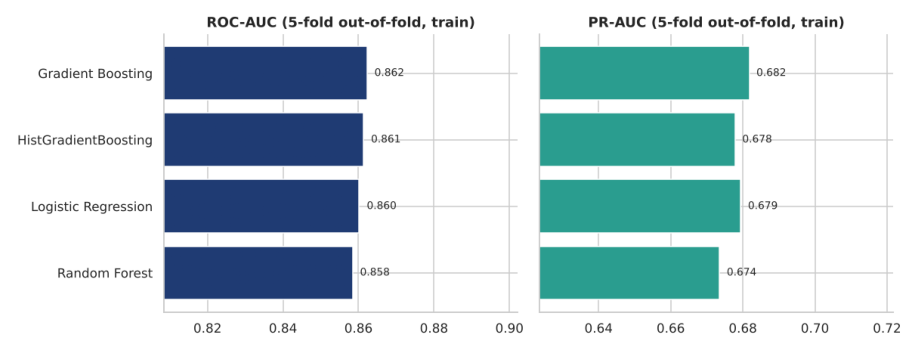

In [10]:
show('08_model_comparison.png')

In [11]:
print("Hold-out TEST results for every tuned model at threshold 0.5 (models were NOT selected on this):")
test_tab.drop(columns="threshold").round(4)

Hold-out TEST results for every tuned model at threshold 0.5 (models were NOT selected on this):


,roc_auc,pr_auc,accuracy,precision,recall,f1,brier
Logistic Regression,0.8524,0.6612,0.8055,0.6623,0.5455,0.5982,0.1340
Random Forest,0.8529,0.6672,0.7729,0.5511,0.7781,0.6452,0.1517
Gradient Boosting,0.8545,0.6719,0.8126,0.6763,0.5642,0.6152,0.1330
HistGradientBoosting,0.8537,0.6707,0.8055,0.6656,0.5374,0.5947,0.1335


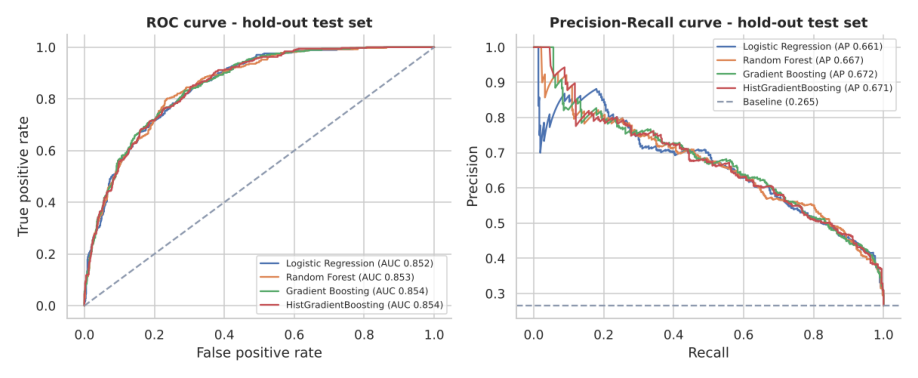

In [12]:
show('09_roc_pr_test.png')

### Final model - detailed hold-out performance

In [13]:
res = pd.DataFrame({"threshold 0.50": summary["test_at_0.5"], f"chosen {summary['threshold_chosen_on_oof_f1']:.2f}": summary["test_at_chosen_threshold"]}).drop("threshold")
print(f"ROC-AUC 95% bootstrap CI: {summary['test_roc_auc_95ci'][0]:.3f} - {summary['test_roc_auc_95ci'][1]:.3f}")
print(f"PR-AUC  95% bootstrap CI: {summary['test_pr_auc_95ci'][0]:.3f} - {summary['test_pr_auc_95ci'][1]:.3f}")
res.round(4)

ROC-AUC 95% bootstrap CI: 0.834 - 0.874
PR-AUC  95% bootstrap CI: 0.622 - 0.720


,threshold 0.50,chosen 0.33
roc_auc,0.8545,0.8545
pr_auc,0.6719,0.6719
accuracy,0.8126,0.7779
precision,0.6763,0.5631
recall,0.5642,0.7273
f1,0.6152,0.6348
brier,0.1330,0.1330


In [14]:
from sklearn.metrics import confusion_matrix, classification_report
thr = summary["threshold_chosen_on_oof_f1"]
best = tuned[summary["selected_model"]].best_estimator_
p = best.predict_proba(Xte)[:, 1]
print(confusion_matrix(yte, p >= thr))
print(classification_report(yte, p >= thr, target_names=["Stay", "Churn"], digits=3))

[[824 211]
 [102 272]]
              precision    recall  f1-score   support

        Stay      0.890     0.796     0.840      1035
       Churn      0.563     0.727     0.635       374

    accuracy                          0.778      1409
   macro avg      0.726     0.762     0.738      1409
weighted avg      0.803     0.778     0.786      1409



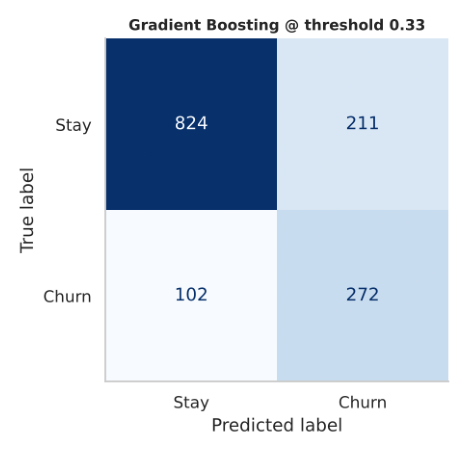

In [15]:
show('10_confusion_matrix.png', 5)

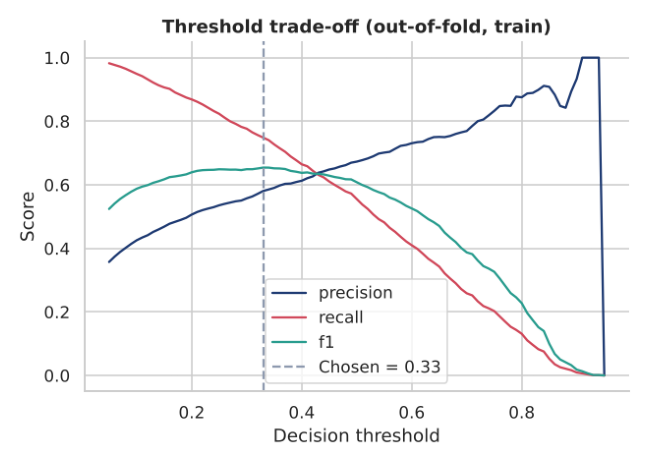

In [16]:
show('15_threshold_tradeoff.png', 7)

### Does the probability mean something? (calibration)

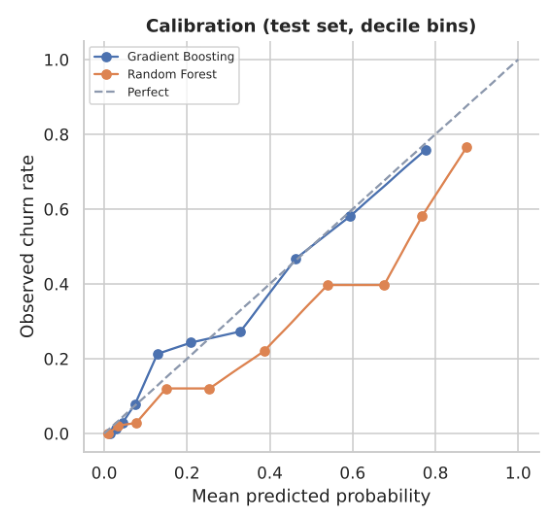

In [17]:
show('11_calibration.png', 6)

### Business view: risk deciles, lift and gains

In [18]:
lift.round(3)

,decile,customers,churners,churn_rate,avg_score,lift,cum_capture
0,1,141,107,0.759,0.776,2.859,0.286
1,2,141,82,0.582,0.594,2.191,0.505
2,3,141,65,0.461,0.462,1.737,0.679
3,4,141,39,0.277,0.328,1.042,0.783
4,5,141,35,0.248,0.209,0.935,0.877
5,6,140,29,0.207,0.128,0.780,0.955
6,7,141,11,0.078,0.075,0.294,0.984
7,8,141,4,0.028,0.044,0.107,0.995
8,9,141,2,0.014,0.028,0.053,1.000
9,10,141,0,0.000,0.013,0.000,1.000


In [19]:
print(f"Contacting the top 20% highest-risk customers captures {summary['top20pct_capture']:.1%} of all churners (random targeting would capture 20%).")
print(f"Top-decile churn rate: {summary['top10pct_churn_rate']:.1%} vs overall {summary['test_churn_rate']:.1%}.")

Contacting the top 20% highest-risk customers captures 50.5% of all churners (random targeting would capture 20%).
Top-decile churn rate: 75.9% vs overall 26.5%.


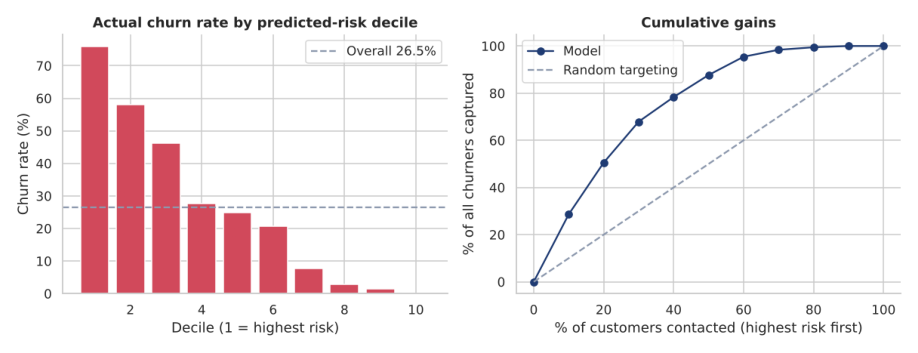

In [20]:
show('12_lift_gains.png')

## 7. Interpretation: what drives the predictions?

In [21]:
imp.sort_values("mean", ascending=False).round(4).head(12)

,mean,std
tenure_months,0.0881,0.0058
contract,0.0457,0.0050
dependents,0.0310,0.0048
internet_service,0.0297,0.0059
payment_method,0.0028,0.0015
paperless_billing,0.0023,0.0009
phone_service,0.0021,0.0010
monthly_charges,0.0019,0.0013
tech_support,0.0017,0.0008
partner,0.0017,0.0006


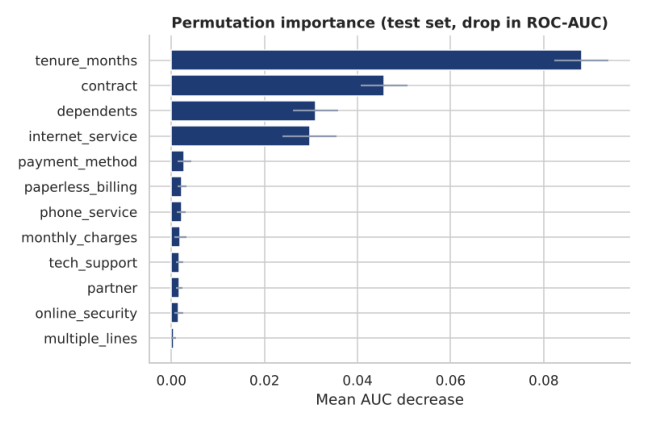

In [22]:
show('13_permutation_importance.png', 7)

Permutation importance is computed on the **raw input columns** of the whole pipeline (engineered features are re-derived after shuffling), so it answers: *'how much does the model rely on this piece of customer information?'* For direction of effect we use the tuned logistic regression below.

In [23]:
print("Most churn-increasing / churn-reducing standardised effects (LR):")
pd.concat([coefs.head(8).round(3), coefs.tail(8).round(3)]).to_frame("coef")

Most churn-increasing / churn-reducing standardised effects (LR):


,coef
dependents,-1.466
contract_Two year,-0.698
tenure_months,-0.637
phone_service,-0.578
internet_service_No,-0.376
n_protective,-0.236
tenure_bucket_13-24,-0.232
online_security,-0.229
payment_method_Electronic check,0.207
partner,0.268


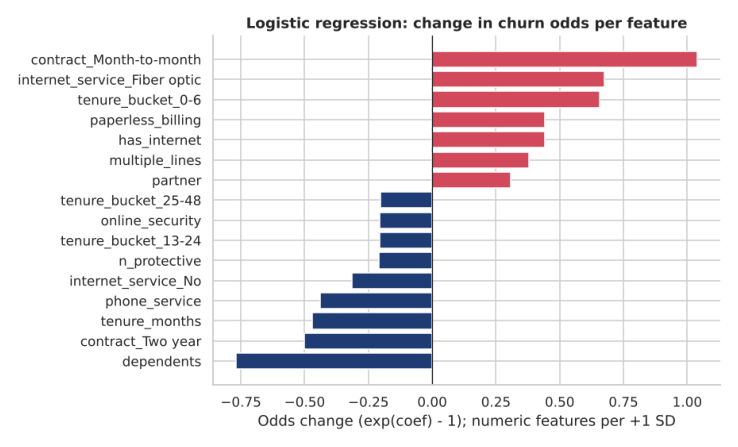

In [24]:
show('14_lr_odds_ratios.png', 8)

**Caution:** `tenure_months`, `total_charges`, `avg_monthly_spend` and `monthly_charges` are strongly correlated, so individual coefficients among them are unstable and should be read together, not one at a time.

## 8. Where does the model struggle? (performance by segment, test set)

In [25]:
from sklearn.metrics import precision_score, recall_score, roc_auc_score
seg = Xte.assign(y=yte.values, p=p, pred=(p >= thr).astype(int))
rows = {}
for col in ["contract", "internet_service", "senior_citizen"]:
    for v, g in seg.groupby(col):
        rows[f"{col} = {v}"] = {"n": len(g), "churn_rate": g.y.mean(), "recall": recall_score(g.y, g.pred, zero_division=0),
                                "precision": precision_score(g.y, g.pred, zero_division=0),
                                "auc": roc_auc_score(g.y, g.p) if g.y.nunique() > 1 else np.nan}
pd.DataFrame(rows).T.round(3)

,n,churn_rate,recall,precision,auc
contract = Month-to-month,773.0,0.426,0.818,0.569,0.761
contract = One year,300.0,0.120,0.083,0.300,0.824
contract = Two year,336.0,0.027,0.000,0.000,0.831
internet_service = DSL,484.0,0.200,0.557,0.535,0.833
internet_service = Fiber optic,613.0,0.411,0.841,0.576,0.796
internet_service = No,312.0,0.080,0.240,0.429,0.883
senior_citizen = 0,1187.0,0.233,0.688,0.543,0.860
senior_citizen = 1,222.0,0.441,0.837,0.617,0.773


Segments with very few churners (e.g. two-year contracts) give unstable metrics - treat those rows with caution.

## 9. Reload the saved model and verify

In [26]:
loaded = joblib.load(C.MODEL_DIR / "best_model.joblib")
same = np.allclose(loaded.predict_proba(Xte)[:, 1], p)
print("Reloaded model reproduces test probabilities exactly:", same)
meta = json.load(open(C.MODEL_DIR / "model_metadata.json")); meta

Reloaded model reproduces test probabilities exactly: True


{'model': 'Gradient Boosting', 'threshold': 0.33, 'input_columns': ['senior_citizen', 'partner', 'dependents', 'tenure_months', 'phone_service', 'multiple_lines', 'internet_service', 'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies', 'contract', 'paperless_billing', 'payment_method', 'monthly_charges', 'total_charges'], 'sklearn_version': '1.9.1', 'python_version': '3.12.3', 'seed': 42, 'trained_on_rows': 5634, 'note': 'Trained on the 80% training split. Needs `src` importable when loading (custom engineer function).'}

In [27]:
sample = Xte.head(5).copy()
sample["churn_probability"] = loaded.predict_proba(sample)[:, 1].round(3)
sample["risk_tier"] = pd.cut(sample.churn_probability, [0, .3, .6, 1], labels=["Low", "Medium", "High"], include_lowest=True)
sample["actual_churn"] = yte.head(5).values
sample[["contract", "internet_service", "tenure_months", "monthly_charges", "churn_probability", "risk_tier", "actual_churn"]]

,contract,internet_service,tenure_months,monthly_charges,churn_probability,risk_tier,actual_churn
2196,Two year,Fiber optic,72,114.05,0.075,Low,0
3549,Month-to-month,Fiber optic,8,100.15,0.793,High,0
3515,One year,DSL,41,78.35,0.096,Low,0
5162,Month-to-month,Fiber optic,18,78.20,0.405,Medium,0
4642,Two year,DSL,72,82.65,0.036,Low,0


In [28]:
print(json.dumps({k: v for k, v in summary.items() if k not in ("best_params",)}, indent=2, default=str))

{
  "selected_model": "Gradient Boosting",
  "selection_rule": "highest mean 5-fold CV ROC-AUC on the training split",
  "cv_roc_auc_mean": 0.8630422098355138,
  "threshold_chosen_on_oof_f1": 0.33,
  "test_at_0.5": {
    "threshold": 0.5,
    "roc_auc": 0.8544963703531477,
    "pr_auc": 0.6718864840435754,
    "accuracy": 0.8126330731014905,
    "precision": 0.6762820512820513,
    "recall": 0.5641711229946524,
    "f1": 0.6151603498542274,
    "brier": 0.13296920739355175
  },
  "test_at_chosen_threshold": {
    "threshold": 0.33,
    "roc_auc": 0.8544963703531477,
    "pr_auc": 0.6718864840435754,
    "accuracy": 0.7778566359119943,
    "precision": 0.5631469979296067,
    "recall": 0.7272727272727273,
    "f1": 0.6347724620770129,
    "brier": 0.13296920739355175
  },
  "test_roc_auc_95ci": [
    0.8337585040035653,
    0.8735020561411883
  ],
  "test_pr_auc_95ci": [
    0.6215856541380232,
    0.7201012708313139
  ],
  "top20pct_capture": 0.5053475935828877,
  "top10pct_churn_rate"